# Label noise: memorization, early stopping and weight averaging

Some training labels are wrong: a tired annotator, a misclick, a bad heuristic.
A neural network big enough can learn even the wrong labels by heart. That is **memorization**, and it costs accuracy on new data.

This notebook flips a tenth of the labels on a small image dataset, trains a small network, and watches it memorize.
Then it tries two cheap remedies from the OPAL slide (Bai et al., "Reactive Optimizers", [arXiv:2610.33826](https://arxiv.org/abs/2610.33826)):

- **Early stopping:** keep the weights from the epoch that did best on a validation set.
- **Weight averaging** (Stochastic Weight Averaging, Izmailov et al. 2018, [arXiv:1803.05407](https://arxiv.org/abs/1803.05407)): average the weights over many epochs instead of keeping the last ones.

**Data:** scikit-learn's handwritten digits: 1,797 images of 8 by 8 pixels, digits 0 to 9.
It ships with scikit-learn (BSD licence), a copy of the UCI "Optical Recognition of Handwritten Digits" test set (CC BY 4.0), so nothing is downloaded.
The whole notebook runs in under a minute on a laptop CPU.

In [1]:
import copy

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from torch import nn
from torch.optim.swa_utils import AveragedModel

torch.set_num_threads(2)  # a network this small runs slower with more threads

## 1. Data, with a tenth of the labels flipped

Three splits: training (with wrong labels), validation (also with wrong labels, as it would be in real life),
and a clean test set to measure what the model really learned.
Each flipped label moves to a different, random digit.

train 1005 images, 100 with a wrong label; validation 252; test 540 (clean)


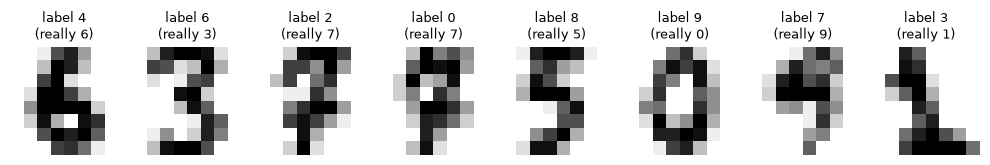

In [2]:
X, y = load_digits(return_X_y=True)
X = (X / 16).astype(np.float32)  # pixel values 0 to 16 -> 0 to 1

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=0)


def flip_labels(labels, fraction, rng):
    "Give `fraction` of the labels a different, random digit. Returns the noisy labels and which ones changed."
    noisy = labels.copy()
    flipped = rng.choice(len(labels), int(fraction * len(labels)), replace=False)
    noisy[flipped] = (labels[flipped] + rng.integers(1, 10, len(flipped))) % 10
    return noisy, flipped


rng = np.random.default_rng(0)
y_train_noisy, flipped = flip_labels(y_train, 0.10, rng)
y_val_noisy, _ = flip_labels(y_val, 0.10, rng)
print(f"train {len(X_train)} images, {len(flipped)} with a wrong label; validation {len(X_val)}; test {len(X_test)} (clean)")

fig, axes = plt.subplots(1, 8, figsize=(10, 1.8))
for ax, i in zip(axes, flipped[:8]):
    ax.imshow(X_train[i].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"label {y_train_noisy[i]}\n(really {y_train[i]})", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. One training run, three ways to pick the final weights

A network with two hidden layers of 512 units: far more capacity than 1,000 small images need, so it *can* memorize.
It trains for 100 epochs with plain SGD at a fairly high learning rate (0.3).

The same run gives all three models, so the comparison is fair:

- **Plain:** the weights after the last epoch.
- **Early stopping:** the weights from the epoch with the best accuracy on the (noisy) validation set.
  Here we train to the end and keep the best copy. In practice you stop once validation stops improving.
- **Weight average:** `AveragedModel` keeps a running average of the weights from epoch 5 on.
  The network has no batch normalization, so the average needs no extra step.

After every epoch we measure **memorized**: the share of the wrongly labelled training images that the model predicts *with their wrong label*.

In [3]:
EPOCHS, LEARNING_RATE, BATCH, AVERAGE_FROM = 100, 0.3, 32, 5


def make_model():
    return nn.Sequential(nn.Linear(64, 512), nn.ReLU(), nn.Linear(512, 512), nn.ReLU(), nn.Linear(512, 10))


@torch.no_grad()
def evaluate(model, data):
    "Memorized share of the flipped labels, clean test accuracy, noisy validation accuracy."
    X_tr, X_va, X_te = data
    pred = model(X_tr).argmax(1).numpy()
    return {"memorized": (pred[flipped] == y_train_noisy[flipped]).mean(),
            "test accuracy": (model(X_te).argmax(1).numpy() == y_test).mean(),
            "validation accuracy": (model(X_va).argmax(1).numpy() == y_val_noisy).mean()}


def train(seed):
    torch.manual_seed(seed)
    data = tuple(torch.tensor(a) for a in (X_train, X_val, X_test))
    targets = torch.tensor(y_train_noisy)
    model = make_model()
    optimizer = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE)
    averaged = AveragedModel(model)
    loss_fn = nn.CrossEntropyLoss()
    history, best = [], {"validation accuracy": -1}
    for epoch in range(EPOCHS):
        order = torch.randperm(len(targets))
        for start in range(0, len(order), BATCH):
            batch = order[start:start + BATCH]
            optimizer.zero_grad()
            loss_fn(model(data[0][batch]), targets[batch]).backward()
            optimizer.step()
        if epoch >= AVERAGE_FROM:
            averaged.update_parameters(model)
        plain = evaluate(model, data)
        history.append({"epoch": epoch + 1, **plain,
                        **({f"{k} (average)": v for k, v in evaluate(averaged, data).items()} if epoch >= AVERAGE_FROM else {})})
        if plain["validation accuracy"] > best["validation accuracy"]:
            best = {**plain, "epoch": epoch + 1, "weights": copy.deepcopy(model.state_dict())}
    early = make_model()
    early.load_state_dict(best["weights"])
    finals = {"Plain": evaluate(model, data), "Early stopping": evaluate(early, data),
              "Weight average": evaluate(averaged, data)}
    return pd.DataFrame(history).set_index("epoch"), finals, best["epoch"]


history, finals, best_epoch = train(seed=0)
print("Early stopping picked epoch", best_epoch)

Early stopping picked epoch 19


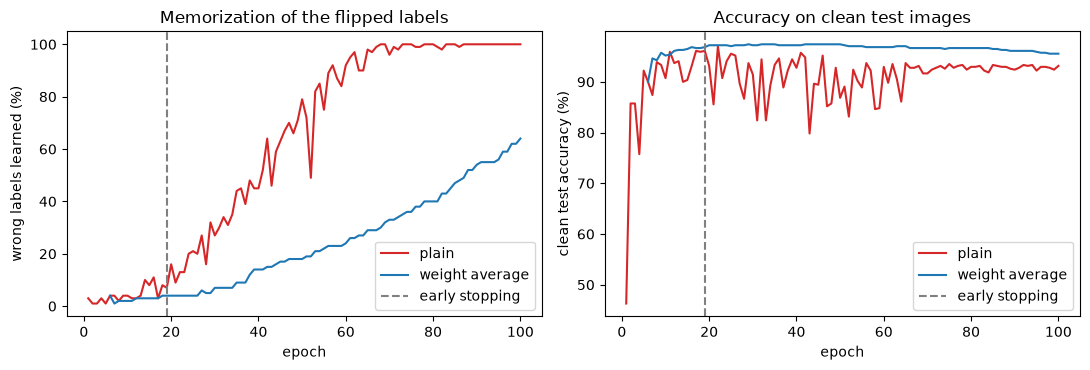

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.plot(history["memorized"] * 100, label="plain", color="tab:red")
ax1.plot(history["memorized (average)"] * 100, label="weight average", color="tab:blue")
ax1.set_ylabel("wrong labels learned (%)")
ax2.plot(history["test accuracy"] * 100, label="plain", color="tab:red")
ax2.plot(history["test accuracy (average)"] * 100, label="weight average", color="tab:blue")
ax2.set_ylabel("clean test accuracy (%)")
for ax in (ax1, ax2):
    ax.axvline(best_epoch, color="grey", linestyle="--", label="early stopping")
    ax.set_xlabel("epoch")
    ax.legend()
ax1.set_title("Memorization of the flipped labels")
ax2.set_title("Accuracy on clean test images")
plt.tight_layout()
plt.show()

For the first 15 or so epochs the network learns the real digits and ignores the wrong labels:
easy, shared patterns are learned before exceptions (Arpit et al. 2017, [arXiv:1706.05394](https://arxiv.org/abs/1706.05394)).
Then it starts to learn the wrong labels one by one, until it has them all by heart.
Test accuracy drops as it does: each memorized exception bends the model a little away from the real digits.

The plain model's test accuracy also jumps around from epoch to epoch, because the learning rate is high.
The average is smooth: averaging cancels out much of that noise.

                memorized  test accuracy
Plain               100.0           93.1
Early stopping        7.0           96.1
Weight average       64.0           95.6


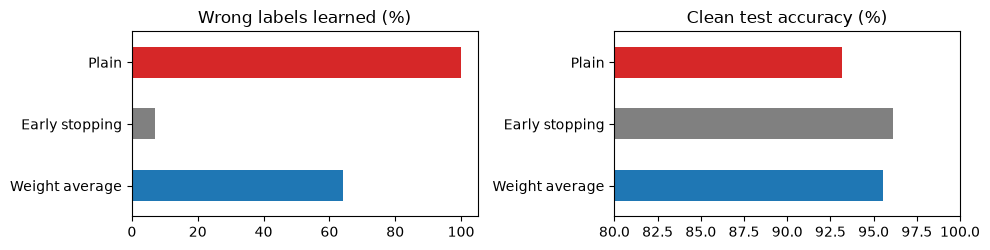

In [5]:
summary = pd.DataFrame(finals).T[["memorized", "test accuracy"]] * 100
print(summary.round(1).to_string())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 2.6))
colors = ["tab:red", "grey", "tab:blue"]
summary["memorized"].plot.barh(ax=ax1, color=colors, title="Wrong labels learned (%)")
summary["test accuracy"].plot.barh(ax=ax2, color=colors, title="Clean test accuracy (%)", xlim=(80, 100))
for ax in (ax1, ax2):
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 3. One run is an anecdote

Different random starts give different numbers. Three seeds (about 20 seconds):

In [6]:
rows = []
for seed in (0, 1, 2):
    _, f, _ = train(seed)
    rows += [{"seed": seed, "model": name, **{k: v * 100 for k, v in m.items() if k != "validation accuracy"}}
             for name, m in f.items()]
seeds = pd.DataFrame(rows).groupby("model", sort=False)[["memorized", "test accuracy"]].agg(["mean", "min", "max"])
print(seeds.round(1).to_string())

               memorized               test accuracy            
                    mean    min    max          mean   min   max
model                                                           
Plain              100.0  100.0  100.0          92.7  91.3  93.7
Early stopping       3.3    0.0    7.0          95.9  94.6  96.9
Weight average      59.3   53.0   64.0          95.4  95.2  95.6


## What this shows

- **Plain training memorizes every wrong label**, and clean test accuracy falls by a few points from its early peak.
- **Early stopping** catches the model before it memorizes: it learns almost none of the wrong labels and keeps the best test accuracy.
  It needs a validation set, and here a noisy one was good enough.
- **Weight averaging** needs no validation set. After 100 epochs the average has learned about 60% of the wrong labels, against 100% for the plain model, and its test accuracy is close to early stopping's.
  The average lags behind the latest weights, which are the ones learning the exceptions. Run it long enough and the average memorizes too.
- The OPAL paper (ResNet-18, CIFAR-10, a tenth of the labels wrong) puts AdamW at 100% memorized, early stopping at 19.4%, weight averaging at 14.2% and OPAL at 3.7%.
  Here early stopping beats averaging; in the paper it is the other way round. Which simple remedy wins depends on the setup.
  The lesson holds either way: run the simple baselines before crediting a clever method.

Try:

- Start averaging later (`AVERAGE_FROM = 40`): once the weights being averaged have memorized, the average has too.
- 20% or 40% wrong labels.
- `torch.optim.Adam(model.parameters(), lr=1e-3)` instead of SGD: it memorizes faster.
- Add weight decay (`weight_decay=1e-3` in the optimizer) or a dropout layer, and compare.